In [1]:
#google drive a bağlanma
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Toplam veri: 360
Feature boyutu: 651
Train: 288 Test: 72

TONE MODEL
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Tone acc: 0.8888888888888888
              precision    recall  f1-score   support

   aggresive       0.83      0.83      0.83        24
       happy       0.91      0.83      0.87        24
     neutral       0.92      1.00      0.96        24

    accuracy                           0.89        72
   macro avg       0.89      0.89      0.89        72
weighted avg       0.89      0.89      0.89        72



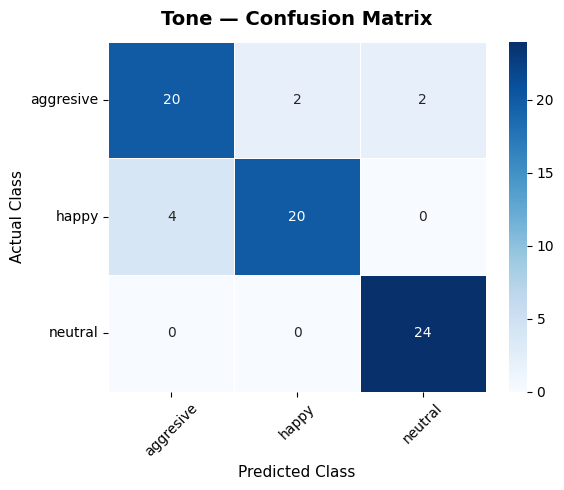

Kaydedildi: confusion_matrix_tone.png


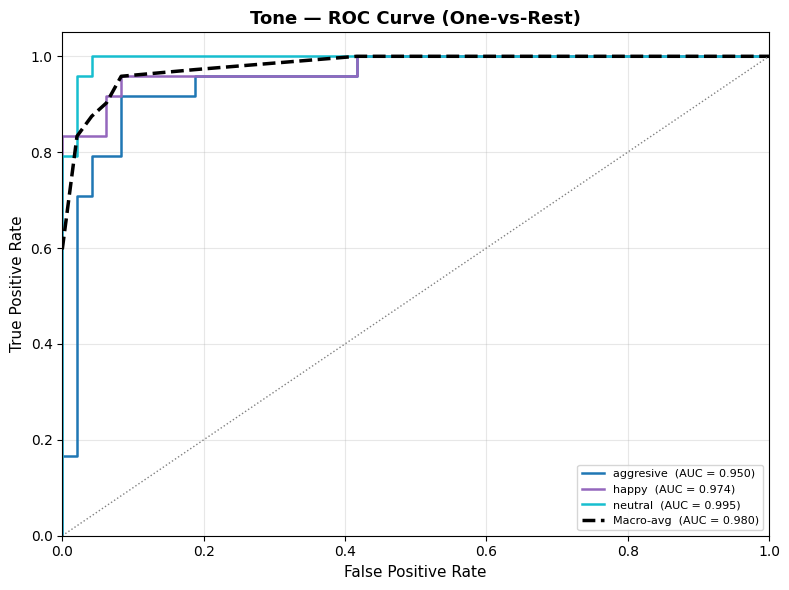

Kaydedildi: roc_curve_tone.png

CONTENT MODEL
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Content acc: 0.6111111111111112
              precision    recall  f1-score   support

     hateful       0.60      0.88      0.71        24
     neutral       0.65      0.52      0.58        21
    positive       0.60      0.44      0.51        27

    accuracy                           0.61        72
   macro avg       0.62      0.61      0.60        72
weighted avg       0.61      0.61      0.60        72



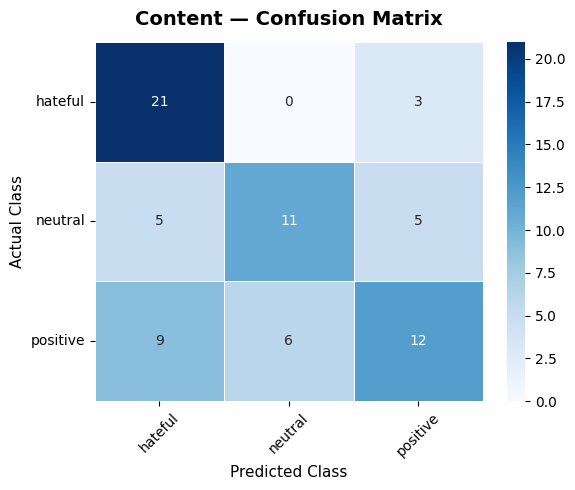

Kaydedildi: confusion_matrix_content.png


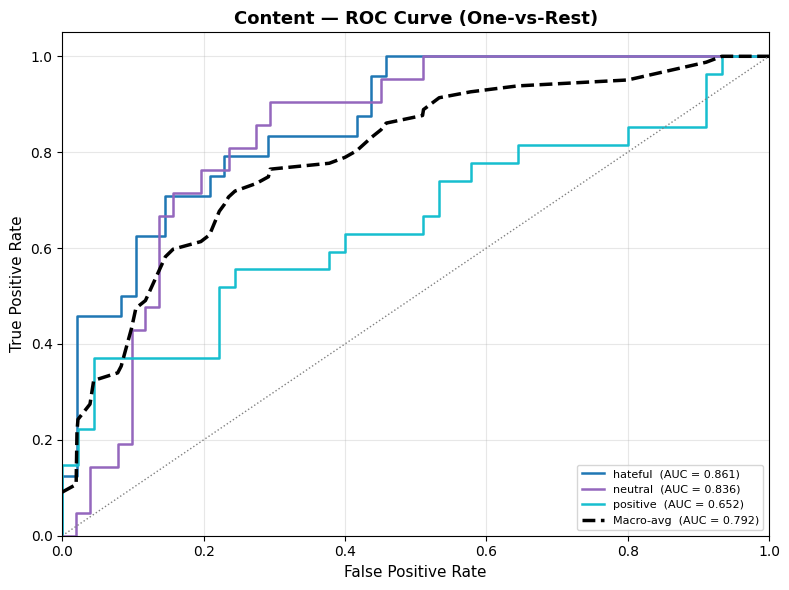

Kaydedildi: roc_curve_content.png

Model kaydedildi.
Grafikler: confusion_matrix_tone/content.png, roc_curve_tone/content.png


In [2]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import librosa

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.model_selection import GroupShuffleSplit, GridSearchCV
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, accuracy_score
)

warnings.filterwarnings("ignore")


# ============================================================
# FEATURE EXTRACTION
# ============================================================

def extract_features(y, sr):
    try:
        y, _ = librosa.effects.trim(y, top_db=20)
        y = librosa.util.normalize(y)
        feats = []

        rms = librosa.feature.rms(y=y).ravel()
        feats += [rms.mean(), rms.std()]

        zcr = librosa.feature.zero_crossing_rate(y).ravel()
        feats += [zcr.mean(), zcr.std()]

        onset_env = librosa.onset.onset_strength(y=y, sr=sr)
        tempo = librosa.beat.tempo(onset_envelope=onset_env, sr=sr)[0]
        feats.append(float(tempo))

        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=60)
        feats += list(mfcc.mean(axis=1))
        feats += list(mfcc.std(axis=1))

        delta = librosa.feature.delta(mfcc)
        feats += list(delta.mean(axis=1) * 1.5)
        feats += list(delta.std(axis=1))

        delta2 = librosa.feature.delta(mfcc, order=2)
        feats += list(delta2.mean(axis=1) * 1.5)
        feats += list(delta2.std(axis=1))

        centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
        feats += [centroid.mean(), centroid.std()]

        bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)
        feats += [bandwidth.mean(), bandwidth.std()]

        rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)
        feats += [rolloff.mean(), rolloff.std()]

        chroma = librosa.feature.chroma_stft(y=y, sr=sr)
        feats += list(chroma.mean(axis=1))
        feats += list(chroma.std(axis=1))

        mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
        mel_db = librosa.power_to_db(mel)
        feats += list(mel_db.mean(axis=1))
        feats += list(mel_db.std(axis=1))

        return np.array(feats, dtype=np.float32)

    except Exception as e:
        print("Feature error:", e)
        return None


# ============================================================
# GÖRSELLEŞTIRME YARDIMCI FONKSİYONLARI
# ============================================================

def plot_confusion_matrix(y_true, y_pred, class_names, title, filename):
    """Confusion matrix grafiği oluşturur ve kaydeder."""
    cm = confusion_matrix(y_true, y_pred)

    fig, ax = plt.subplots(figsize=(max(6, len(class_names) * 1.5),
                                    max(5, len(class_names) * 1.3)))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        linewidths=0.5,
        linecolor="white",
        ax=ax
    )

    ax.set_title(title, fontsize=14, fontweight="bold", pad=12)
    ax.set_xlabel("Predicted Class", fontsize=11)
    ax.set_ylabel("Actual Class", fontsize=11)
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Kaydedildi: {filename}")


def plot_roc_curve(y_true, y_prob, class_names, title, filename):
    """
    Çok sınıflı ROC eğrisi (One-vs-Rest) çizer ve kaydeder.
    İkili sınıf durumunda da çalışır.
    """
    n_classes = len(class_names)

    # İkili sınıf
    if n_classes == 2:
        fpr, tpr, _ = roc_curve(y_true, y_prob[:, 1])
        roc_auc = auc(fpr, tpr)

        fig, ax = plt.subplots(figsize=(6, 5))
        ax.plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc:.3f}")
        ax.plot([0, 1], [0, 1], "k--", lw=1, label="Rastlantısal")
        ax.set_xlabel("False Positive Rate", fontsize=11)
        ax.set_ylabel("True Positive Rate", fontsize=11)
        ax.set_title(title, fontsize=13, fontweight="bold")
        ax.legend(loc="lower right")
        ax.grid(alpha=0.3)

    # Çok sınıflı → One-vs-Rest
    else:
        y_bin = label_binarize(y_true, classes=list(range(n_classes)))

        # Her sınıf için AUC
        fpr_dict, tpr_dict, roc_auc_dict = {}, {}, {}
        for i in range(n_classes):
            fpr_dict[i], tpr_dict[i], _ = roc_curve(y_bin[:, i], y_prob[:, i])
            roc_auc_dict[i] = auc(fpr_dict[i], tpr_dict[i])

        # Macro-average (interpolasyonlu)
        all_fpr = np.unique(np.concatenate([fpr_dict[i] for i in range(n_classes)]))
        mean_tpr = np.zeros_like(all_fpr)
        for i in range(n_classes):
            mean_tpr += np.interp(all_fpr, fpr_dict[i], tpr_dict[i])
        mean_tpr /= n_classes
        macro_auc = auc(all_fpr, mean_tpr)

        # Renk paleti
        colors = plt.cm.tab10(np.linspace(0, 0.9, n_classes))

        fig, ax = plt.subplots(figsize=(8, 6))

        for i, color in zip(range(n_classes), colors):
            ax.plot(
                fpr_dict[i], tpr_dict[i],
                color=color, lw=1.8,
                label=f"{class_names[i]}  (AUC = {roc_auc_dict[i]:.3f})"
            )

        ax.plot(
            all_fpr, mean_tpr,
            color="black", lw=2.5, linestyle="--",
            label=f"Macro-avg  (AUC = {macro_auc:.3f})"
        )
        ax.plot([0, 1], [0, 1], "gray", lw=1, linestyle=":")

        ax.set_xlabel("False Positive Rate", fontsize=11)
        ax.set_ylabel("True Positive Rate", fontsize=11)
        ax.set_title(title, fontsize=13, fontweight="bold")
        ax.legend(loc="lower right", fontsize=8)
        ax.grid(alpha=0.3)

    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Kaydedildi: {filename}")


# ============================================================
# DATASET
# ============================================================

def load_data(csv_path, audio_dir):
    df = pd.read_csv(csv_path)
    X, yt, yc, ids = [], [], [], []

    for _, row in df.iterrows():
        path = os.path.join(audio_dir, row["name"])
        if os.path.exists(path):
            try:
                y, sr = librosa.load(path, sr=22050)
                feat = extract_features(y, sr)
                if feat is not None:
                    X.append(feat)
                    yt.append(row["tone"])
                    yc.append(row["content"])
                    ids.append(row["sentence_id"])
            except:
                continue

    print("Toplam veri:", len(X))
    print("Feature boyutu:", len(X[0]))
    return np.array(X), np.array(yt), np.array(yc), np.array(ids)


# ============================================================
# MODEL
# ============================================================

def build_svm():
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.98)),
        ("svm", SVC(kernel="rbf", probability=True, class_weight=None))
    ])

    param_grid = {
        "svm__C": [100, 300, 500],
        "svm__gamma": [0.0001, 0.001]
    }

    return GridSearchCV(
        pipe, param_grid,
        cv=5, scoring="accuracy",
        n_jobs=-1, verbose=1
    )


# ============================================================
# TRAIN
# ============================================================

def train(csv_path, audio_dir):
    X, yt, yc, ids = load_data(csv_path, audio_dir)

    le_t = LabelEncoder()
    le_c = LabelEncoder()
    yt = le_t.fit_transform(yt)
    yc = le_c.fit_transform(yc)

    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    tr, te = next(gss.split(X, yc, groups=ids))

    Xtr, Xte = X[tr], X[te]
    yt_tr, yt_te = yt[tr], yt[te]
    yc_tr, yc_te = yc[tr], yc[te]

    print("Train:", len(Xtr), "Test:", len(Xte))

    # ================= TONE =================
    print("\nTONE MODEL")
    tone = build_svm()
    tone.fit(Xtr, yt_tr)

    t_pred = tone.predict(Xte)
    t_prob = tone.predict_proba(Xte)

    print("Tone acc:", accuracy_score(yt_te, t_pred))
    print(classification_report(yt_te, t_pred, target_names=le_t.classes_))

    # Tone grafikleri
    plot_confusion_matrix(
        yt_te, t_pred,
        class_names=le_t.classes_,
        title="Tone — Confusion Matrix",
        filename="confusion_matrix_tone.png"
    )
    plot_roc_curve(
        yt_te, t_prob,
        class_names=le_t.classes_,
        title="Tone — ROC Curve (One-vs-Rest)",
        filename="roc_curve_tone.png"
    )

    # ================= CONTENT =================
    print("\nCONTENT MODEL")
    content = build_svm()
    content.fit(Xtr, yc_tr)

    c_pred = content.predict(Xte)
    c_prob = content.predict_proba(Xte)

    print("Content acc:", accuracy_score(yc_te, c_pred))
    print(classification_report(yc_te, c_pred, target_names=le_c.classes_))

    # Content grafikleri
    plot_confusion_matrix(
        yc_te, c_pred,
        class_names=le_c.classes_,
        title="Content — Confusion Matrix",
        filename="confusion_matrix_content.png"
    )
    plot_roc_curve(
        yc_te, c_prob,
        class_names=le_c.classes_,
        title="Content — ROC Curve (One-vs-Rest)",
        filename="roc_curve_content.png"
    )

    # ================= SAVE =================
    joblib.dump(tone.best_estimator_, "svm_tone.pkl")
    joblib.dump(content.best_estimator_, "svm_content.pkl")
    joblib.dump(le_t, "le_tone.pkl")
    joblib.dump(le_c, "le_content.pkl")

    print("\nModel kaydedildi.")
    print("Grafikler: confusion_matrix_tone/content.png, roc_curve_tone/content.png")


# ============================================================
# RUN
# ============================================================

if __name__ == "__main__":
    CSV_PATH  = "/content/drive/MyDrive/HateSpeechProject/Rapor_v1/veriseti/toplamkarisikveriseti/deney/labels.csv"
    AUDIO_DIR = "/content/drive/MyDrive/HateSpeechProject/Rapor_v1/veriseti/toplamkarisikveriseti/deney/sesler"
    train(CSV_PATH, AUDIO_DIR)